# Credit Card Fraud Detection: Model Comparison

Compare three imbalance-handling approaches on the same stratified data split:

1. **XGBoost with `scale_pos_weight`**, trained on the original imbalanced fit data
2. **XGBoost without `scale_pos_weight`**, trained on SMOTE-resampled fit data
3. **Random Forest**, trained on SMOTE-resampled fit data

This keeps class weighting and SMOTE from being combined for the same model. A validation partition selects each model's F1-maximizing probability threshold; the separate test partition is used only for final evaluation. The final section prints confusion matrices, precision, recall, F1, and AUPRC and plots results in the requested order. Place `creditcard.csv` beside this notebook before running it.

In [ ]:
# If needed, install dependencies in your notebook environment:
%pip install xgboost imbalanced-learn scikit-learn pandas numpy matplotlib seaborn

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

RANDOM_STATE = 42


## 1. Load and inspect the data

In [ ]:
df = pd.read_csv('creditcard.csv')
df = df.dropna(subset=['Class']).copy()
df['Class'] = df['Class'].astype(int)

print(f'Dataset shape: {df.shape}')
print('Class counts:')
print(df['Class'].value_counts().sort_index())
print(f"Fraud share: {df['Class'].mean() * 100:.4f}%")
df.head()

Dataset shape: (284807, 31)
Class counts:
Class
0    284315
1       492
Name: count, dtype: int64
Fraud share: 0.1727%


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


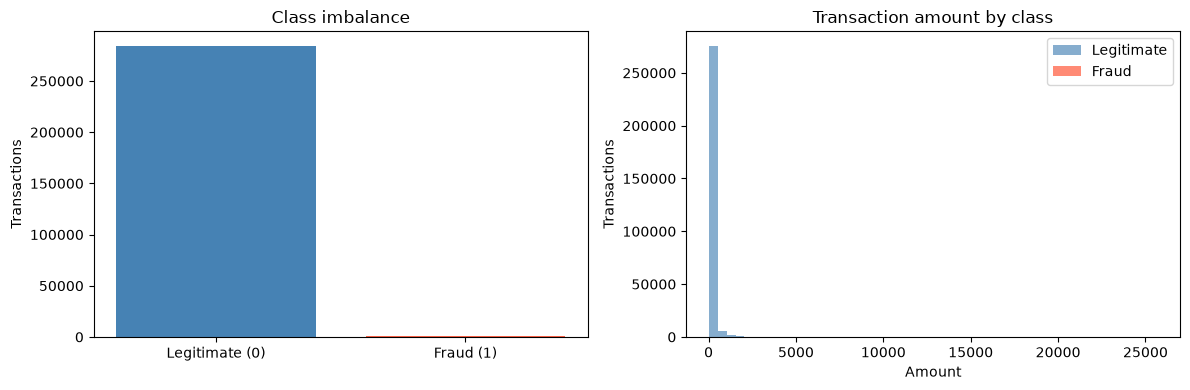

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = df['Class'].value_counts().sort_index()
axes[0].bar(['Legitimate (0)', 'Fraud (1)'], counts.values, color=['steelblue', 'tomato'])
axes[0].set_title('Class imbalance')
axes[0].set_ylabel('Transactions')

axes[1].hist(df.loc[df['Class'] == 0, 'Amount'], bins=50, alpha=0.65, label='Legitimate', color='steelblue')
axes[1].hist(df.loc[df['Class'] == 1, 'Amount'], bins=50, alpha=0.75, label='Fraud', color='tomato')
axes[1].set_title('Transaction amount by class')
axes[1].set_xlabel('Amount')
axes[1].set_ylabel('Transactions')
axes[1].legend()
plt.tight_layout()
plt.show()

## 2. Preprocess and create fit, validation, and test partitions

`Amount` and `Time` are standardized; the PCA features are already scaled. A stratified validation partition from the training data is reserved for threshold selection. SMOTE is applied only to the fit partition.

In [ ]:
scaler = StandardScaler()
df['Amount_scaled'] = scaler.fit_transform(df[['Amount']])
df['Time_scaled'] = scaler.fit_transform(df[['Time']])

X = df.drop(columns=['Class', 'Amount', 'Time'])
y = df['Class']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE
)

smote = SMOTE(random_state=RANDOM_STATE)
X_fit_res, y_fit_res = smote.fit_resample(X_fit, y_fit)

print(f'Model-fit rows before SMOTE: {len(X_fit):,}')
print(f'Model-fit rows after SMOTE:  {len(X_fit_res):,}')
print(f'Validation rows:             {len(X_val):,}')
print(f'Test rows (held out):        {len(X_test):,}')

Model-fit rows before SMOTE: 182,276
Model-fit rows after SMOTE:  363,922
Validation rows:             45,569
Test rows (held out):        56,962


## 3. Train the three methods

The weighted XGBoost uses the original imbalanced fit partition and receives the class ratio through `scale_pos_weight`. The other two methods use SMOTE-resampled fit data and no additional class weighting.

In [ ]:
scale_pos_weight = (y_fit == 0).sum() / (y_fit == 1).sum()

models = {
    'XGBoost': XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.05,
        scale_pos_weight=scale_pos_weight, eval_metric='aucpr',
        random_state=RANDOM_STATE, n_jobs=-1,
    ),
    'XGBoost without scale_pos_weight': XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.05,
        eval_metric='aucpr', random_state=RANDOM_STATE, n_jobs=-1,
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=300, max_depth=10, random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

# Class weighting and SMOTE are evaluated as separate imbalance strategies.
models['XGBoost'].fit(X_fit, y_fit)
models['XGBoost without scale_pos_weight'].fit(X_fit_res, y_fit_res)
models['Random Forest'].fit(X_fit_res, y_fit_res)
print('All three models trained.')

All three models trained.


## 4. Select thresholds on validation data

For each model, select the threshold that maximizes F1 on the validation partition. `precision_recall_curve` returns one more precision/recall point than thresholds, so F1 uses `precision[:-1]` and `recall[:-1]` to keep values aligned.

In [ ]:
model_order = ['XGBoost', 'XGBoost without scale_pos_weight', 'Random Forest']
thresholds_by_model = {}

for name in model_order:
    val_probabilities = models[name].predict_proba(X_val)[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_val, val_probabilities)
    val_f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    best_idx = int(np.argmax(val_f1))
    thresholds_by_model[name] = float(thresholds[best_idx])
    print(
        f'{name}: threshold={thresholds_by_model[name]:.6f}, '
        f'validation precision={precision[best_idx]:.4f}, '
        f'recall={recall[best_idx]:.4f}, F1={val_f1[best_idx]:.4f}'
    )

print('\nThresholds are fixed; the test set is used only for final evaluation.')

XGBoost: threshold=0.939168, validation precision=0.9531, recall=0.7722, F1=0.8531
XGBoost without scale_pos_weight: threshold=0.910686, validation precision=0.9118, recall=0.7848, F1=0.8435
Random Forest: threshold=0.738757, validation precision=0.8551, recall=0.7468, F1=0.7973

Thresholds are fixed; the test set is used only for final evaluation.



XGBoost (validation-selected threshold = 0.939168)
Confusion matrix (rows = actual [0, 1], columns = predicted [0, 1]):
[[56860     4]
 [   20    78]]
Precision: 0.9512
Recall:    0.7959
F1:        0.8667
AUPRC:     0.8756

XGBoost without scale_pos_weight (validation-selected threshold = 0.910686)
Confusion matrix (rows = actual [0, 1], columns = predicted [0, 1]):
[[56847    17]
 [   17    81]]
Precision: 0.8265
Recall:    0.8265
F1:        0.8265
AUPRC:     0.8559

Random Forest (validation-selected threshold = 0.738757)
Confusion matrix (rows = actual [0, 1], columns = predicted [0, 1]):
[[56838    26]
 [   22    76]]
Precision: 0.7451
Recall:    0.7755
F1:        0.7600
AUPRC:     0.7939


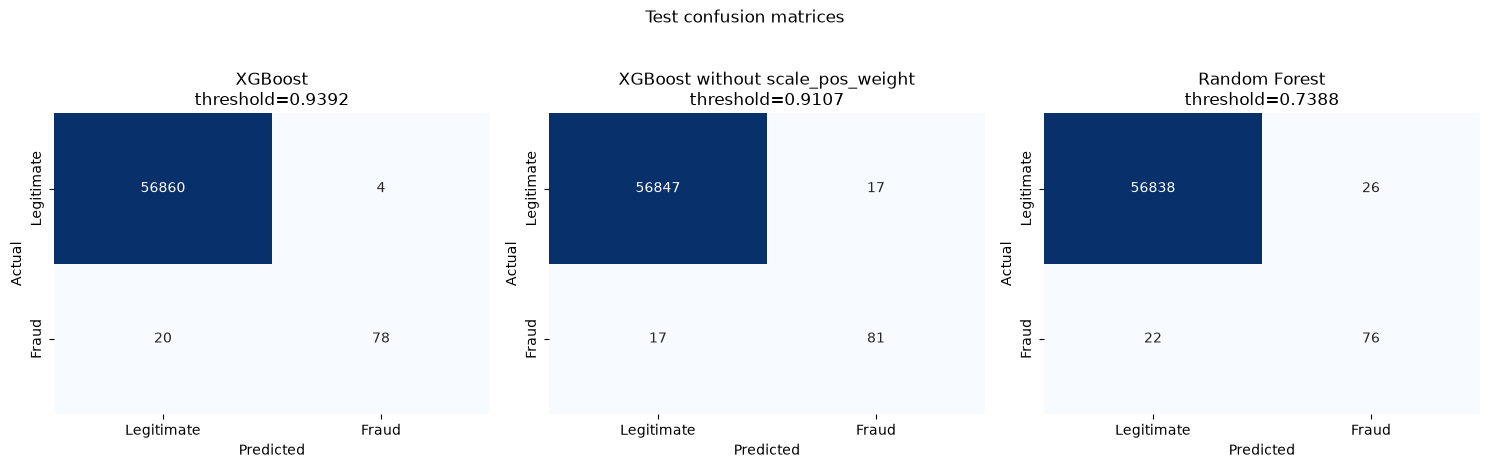

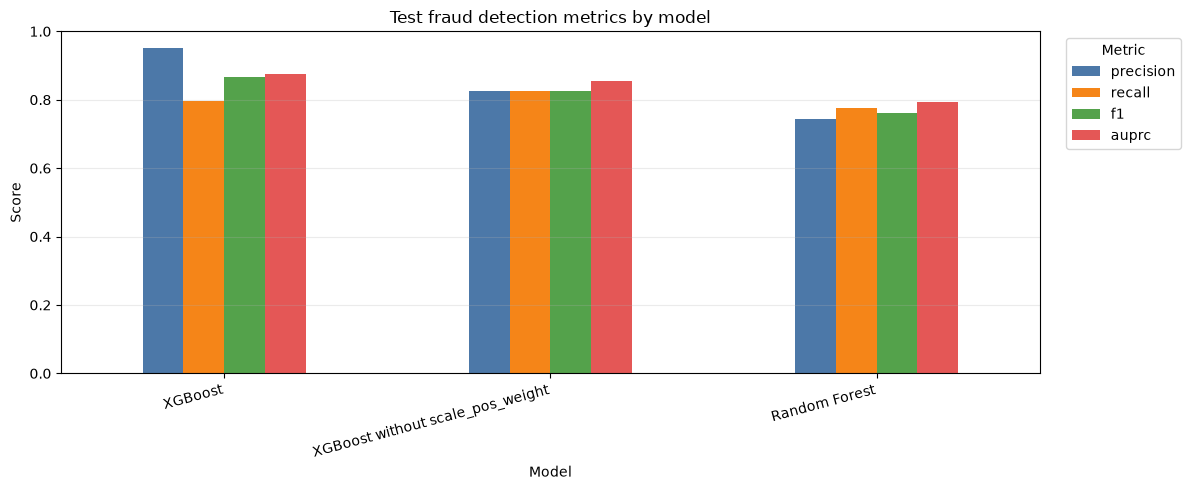

In [ ]:
# Final test evaluation and ordered visual comparison
results = {}
for name in model_order:
    probabilities = models[name].predict_proba(X_test)[:, 1]
    threshold = thresholds_by_model[name]
    predictions = (probabilities >= threshold).astype(int)
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    results[name] = {
        'threshold': threshold,
        'confusion_matrix': cm,
        'precision': precision_score(y_test, predictions, zero_division=0),
        'recall': recall_score(y_test, predictions, zero_division=0),
        'f1': f1_score(y_test, predictions, zero_division=0),
        'auprc': average_precision_score(y_test, probabilities),
    }

for name in model_order:
    result = results[name]
    print(f"\n{name} (validation-selected threshold = {result['threshold']:.6f})")
    print('Confusion matrix (rows = actual [0, 1], columns = predicted [0, 1]):')
    print(result['confusion_matrix'])
    print(f"Precision: {result['precision']:.4f}")
    print(f"Recall:    {result['recall']:.4f}")
    print(f"F1:        {result['f1']:.4f}")
    print(f"AUPRC:     {result['auprc']:.4f}")

metrics = pd.DataFrame(
    {name: {metric: results[name][metric] for metric in ['precision', 'recall', 'f1', 'auprc']}
     for name in model_order}
).T
metrics.index.name = 'Model'

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, name in zip(axes, model_order):
    sns.heatmap(
        results[name]['confusion_matrix'], annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=['Legitimate', 'Fraud'], yticklabels=['Legitimate', 'Fraud'], ax=ax
    )
    ax.set_title(f"{name}\nthreshold={results[name]['threshold']:.4f}")
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
fig.suptitle('Test confusion matrices', y=1.03)
plt.tight_layout()
plt.show()

metrics.plot(kind='bar', figsize=(12, 5), ylim=(0, 1), color=['#4C78A8', '#F58518', '#54A24B', '#E45756'])
plt.title('Test fraud detection metrics by model')
plt.ylabel('Score')
plt.xlabel('Model')
plt.xticks(rotation=15, ha='right')
plt.legend(title='Metric', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

## Training run notes and observed results

The dataset contained **284,807 transactions**, of which **492 (0.1727%)** were fraud. We used one stratified split: 80% for training and 20% for the held-out test set. The training portion was split again into model-fit data and validation data. The validation partition selected each model's threshold by maximizing F1; the test set was reserved for the final statistics.

The model-fit partition had **182,276 transactions** before SMOTE and **363,922** after SMOTE. Weighted XGBoost was trained on the original, imbalanced model-fit partition with `scale_pos_weight`; unweighted XGBoost and Random Forest were trained on the SMOTE-resampled partition. All models trained successfully. The validation-selected thresholds and test-set statistics were:

| Model | Fit strategy | Threshold | Precision | Recall | F1 | AUPRC |
|---|---|---:|---:|---:|---:|---:|
| XGBoost | Original data + `scale_pos_weight` | 0.9392 | 0.9512 | 0.7959 | 0.8667 | 0.8756 |
| XGBoost without `scale_pos_weight` | SMOTE | 0.9107 | 0.8265 | 0.8265 | 0.8265 | 0.8559 |
| Random Forest | SMOTE | 0.7388 | 0.7451 | 0.7755 | 0.7600 | 0.7939 |

### Test confusion matrices

Rows are actual class (`0` legitimate, `1` fraud); columns are predicted class (`0`, `1`).

| Model | True negatives | False positives | False negatives | True positives |
|---|---:|---:|---:|---:|
| XGBoost | 56,860 | 4 | 20 | 78 |
| XGBoost without `scale_pos_weight` | 56,847 | 17 | 17 | 81 |
| Random Forest | 56,838 | 26 | 22 | 76 |

On this split, weighted XGBoost gave the highest precision, F1, and AUPRC, while SMOTE XGBoost caught three more fraud cases (higher recall) at the cost of more false positives. This shows that removing `scale_pos_weight` is a reasonable strategy to compare with SMOTE, but it is not automatically better: here, the weighted XGBoost approach had stronger precision and overall F1. These are single-split results; thresholds were selected for F1, and the model hyperparameters were not tuned. Use a fresh run of the notebook to regenerate the table if the data or model settings change.